# 02 · Vietnamese Review Sentiment Classification

**Goal.** Predict sentiment (negative / neutral / positive) from the *review text*. Use cases:
- label feedback from channels **without star ratings** (support chat, social media, transcribed hotline calls);
- flag reviews whose **rating contradicts the text** (e.g. 5★ but a complaint) so issues are not missed.

**Experimental design**
| Decision | Why |
|---|---|
| Labels from stars (1–2 / 3 / 4–5) | Weak supervision — no labelling cost |
| **Time-based split** (newest 20% as test) | Mirrors deployment; prevents leakage from the future; lets us measure *data drift* |
| Primary metric **macro-F1** | The neutral class is rare, so accuracy would be misleading |
| TF-IDF word 1–2-grams + char 2–5-grams | Syllable bigrams ≈ Vietnamese compound words; char n-grams are robust to typos and missing diacritics |
| `class_weight="balanced"` | Compensates for class imbalance |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from momo_reviews.config import CLEAN_FILE
from momo_reviews.viz import set_style, save, SENTIMENT_COLORS, BLUE, INK_2
set_style()
pd.set_option("display.max_colwidth", 160)

df = pd.read_parquet(CLEAN_FILE)
print(f"{len(df):,} reviews | {df['at'].min():%Y-%m-%d} → {df['at'].max():%Y-%m-%d}")
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from momo_reviews.model import (load_modeling_data, temporal_split, candidate_models, evaluate,
                                top_features, select_model, save_final_model)
from momo_reviews.config import SENTIMENT_ORDER, REPORTS_DIR

217,357 reviews | 2014-05-28 → 2026-10-23


## 1. Training data

In [2]:
data = load_modeling_data(df)
train, test = temporal_split(data, test_size=0.2)
print(f"Dropped {len(df)-len(data):,} empty/spam reviews → {len(data):,} remain")
print(f"Train: {len(train):,}  ({train['at'].min():%Y-%m} – {train['at'].max():%Y-%m})")
print(f"Test : {len(test):,}  ({test['at'].min():%Y-%m} – {test['at'].max():%Y-%m})")
pd.DataFrame({"train": train["sentiment"].value_counts(normalize=True),
              "test": test["sentiment"].value_counts(normalize=True)}).loc[SENTIMENT_ORDER].style.format("{:.1%}")

Dropped 440 empty/spam reviews → 216,917 remain
Train: 173,533  (2014-05 – 2023-12)
Test : 43,384  (2023-12 – 2026-10)


,train,test
sentiment,,
negative,36.5%,45.8%
neutral,4.4%,3.3%
positive,59.1%,50.9%


Raw review vs. normalised text (teencode expanded, emoji → tokens, numbers → `num`):

In [3]:
train[["content", "text_clean", "sentiment"]].sample(6, random_state=1)

,content,text_clean,sentiment
50822,Good,tốt,positive
159113,Ổn,ổn,positive
42306,Quá tiện lợi,quá tiện lợi,positive
2638,Ví MoMo đa số chỉ sử dụng được ở Hà Nội và Tp Hồ Chí Minh.Còn những tỉnh khác thì không thanh toán hóa đơn điện nước được.Tôi ở Tp Huế nên không sử dụng đượ...,ví momo đa số chỉ sử dụng được ở hà nội và tp hồ chí minh còn những tỉnh khác thì không thanh toán hóa đơn điện nước được tôi ở tp huế nên không sử dụng đượ...,negative
141969,Lag vai chương,lag vai chương,negative
94690,Tối ưu phần cứng quá tệ. Chẳng hiểu sao ứng dụng thì nhẹ mà vào là tự thoát như đang vào ứng dụng nặng lắm vậy 😶.,tối ưu phần cứng quá tệ chẳng hiểu sao ứng dụng thì nhẹ mà vào là tự thoát như đang vào ứng dụng nặng lắm vậy,negative


## 2. Model comparison

In [4]:
results, fitted = evaluate(candidate_models(), train, test)
results.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
results.style.format({c: "{:.3f}" for c in results.columns if c not in ("model", "train_seconds")} | {"train_seconds": "{:.0f}s"}) \
       .background_gradient(subset=["macro_f1"], cmap="Blues").hide(axis="index")

model,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive,train_seconds
TF-IDF word+char + LinearSVC,0.656,0.893,0.908,0.129,0.930,552s
TF-IDF word+char + LogReg,0.652,0.881,0.888,0.145,0.922,156s
TF-IDF word + LogReg,0.651,0.881,0.887,0.143,0.922,81s
TF-IDF word + ComplementNB,0.613,0.877,0.897,0.029,0.914,9s
Majority baseline,0.225,0.344,0.000,0.000,0.675,9s


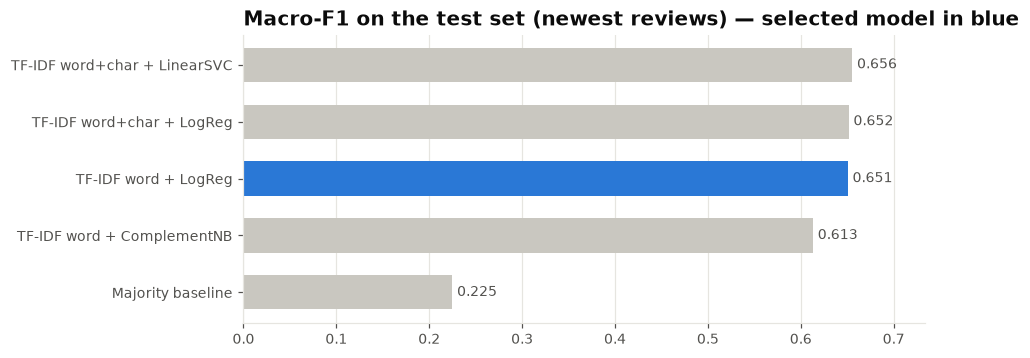

In [5]:
best_name = select_model(results)
r = results.sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(r["model"], r["macro_f1"], color=[BLUE if m == best_name else "#c9c7c0" for m in r["model"]], height=0.6)
for y, v in enumerate(r["macro_f1"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, max(r["macro_f1"]) * 1.12); ax.set_title("Macro-F1 on the test set (newest reviews) — selected model in blue")
ax.grid(axis="y", visible=False)
save(fig, "02_model_comparison"); plt.show()

**Model selection.** The linear TF-IDF models are very close. Selection rule: *the fastest-to-train model within 0.5 macro-F1 points of the best one* — smaller gaps are within noise, while a simpler model is cheaper to retrain regularly and (for Logistic Regression) yields **probabilities** for alert thresholds.

## 3. Detailed evaluation of the selected model

TF-IDF word + LogReg


              precision    recall  f1-score   support

    negative      0.886     0.889     0.887     19862
     neutral      0.108     0.209     0.143      1425
    positive      0.954     0.893     0.922     22097

    accuracy                          0.869     43384
   macro avg      0.649     0.664     0.651     43384
weighted avg      0.895     0.869     0.881     43384



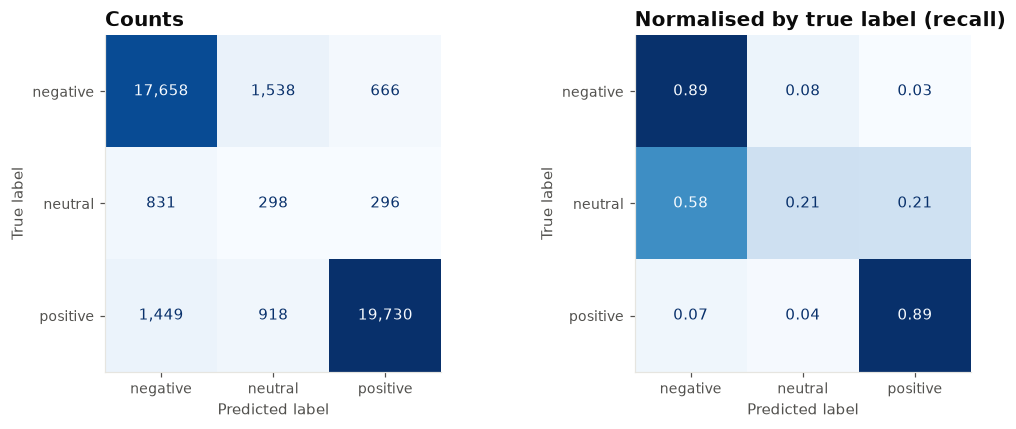

In [6]:
best = fitted[best_name]
test = test.assign(pred=best.predict(test["text_clean"]))
print(best_name)
print(classification_report(test["sentiment"], test["pred"], labels=SENTIMENT_ORDER, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, title in [(axes[0], None, "Counts"), (axes[1], "true", "Normalised by true label (recall)")]:
    ConfusionMatrixDisplay.from_predictions(test["sentiment"], test["pred"], labels=SENTIMENT_ORDER, normalize=norm,
                                            cmap="Blues", ax=ax, colorbar=False, values_format=".2f" if norm else ",d")
    ax.set_title(title); ax.grid(False)
fig.tight_layout(); save(fig, "02_confusion_matrix"); plt.show()

**Reading the confusion matrix.** Negative and positive separate well. Neutral is the hardest class — which *matches the nature of the data*: 3★ reviews mix praise and criticism ("convenient app but often buggy"), and users themselves are inconsistent when choosing 3★.

### What if we drop the neutral class?
In practice the business question is usually *"is this review a complaint?"*. Retraining the same pipeline as a binary negative-vs-positive task:

In [7]:
from sklearn.base import clone
from sklearn.metrics import f1_score, roc_auc_score
tr_b, te_b = train[train.sentiment != "neutral"], test[test.sentiment != "neutral"]
bin_model = clone(fitted["TF-IDF word+char + LogReg"]).fit(tr_b["text_clean"], tr_b["sentiment"])
proba = bin_model.predict_proba(te_b["text_clean"])[:, list(bin_model.classes_).index("negative")]
y_true = (te_b["sentiment"] == "negative").astype(int)
print(f"Binary  F1(negative) = {f1_score(y_true, proba > 0.5):.3f}   "
      f"macro-F1 = {f1_score(y_true, proba > 0.5, average='macro'):.3f}   ROC-AUC = {roc_auc_score(y_true, proba):.3f}")

Binary  F1(negative) = 0.937   macro-F1 = 0.939   ROC-AUC = 0.975


## 4. What did the model learn? (explainability)

In [8]:
feats = top_features(fitted["TF-IDF word + LogReg"], n=15)[["negative", "positive"]]
feats.index = range(1, len(feats) + 1)
feats

,negative,positive
1,không nên,tiện
2,lừa,không mất
3,rác,vẫn cho
4,không uy,tốt mà
5,dụng tệ,tốt ứng
6,bực mình,tien lỗi
7,nuốt,tiên lỗi
8,một sao,tuy nhiên
9,mẹ,nhanh gon
10,rất tệ,còn lại


The highest-weighted n-grams make business sense: negative ↔ *lừa* (scam), *rác* (garbage), *không nên* (don't use), *rất tệ* (very bad); positive ↔ *tiện* (convenient), *nhanh gọn* (quick), *tốt* (good). This builds stakeholder trust and is a sanity check that the model did not latch onto artefacts.

## 5. Error analysis — when the stars "lie"

In [9]:
mismatch = test[(test["sentiment"] == "positive") & (test["pred"] == "negative") & (test["n_words"] >= 6)]
print(f"{len(mismatch):,} reviews rated 4–5★ whose text the model reads as negative ({len(mismatch)/len(test):.1%} of the test set)")
mismatch.sample(min(8, len(mismatch)), random_state=0)[["score", "content"]]

1,051 reviews rated 4–5★ whose text the model reads as negative (2.4% of the test set)


,score,content
205869,5,chuyển trên 5m là tính phí😡
202215,5,Nạp tiền cứ bÁo lỖi kết nối. Lúc được lúc không. Đang sử dụng mạng vnpt xài bình thường.
204164,5,tịnh độ qua rồi.thời kỳ tận độ ra đời quốc bảo chân kinh văn hóa cội nguồn dân tộc Việt Nam.bốn chử Nam mô a men
205671,5,ứng dụng ví điện tử số 1 trên chplay
197581,4,Tui không có mua hàng bên gg mà bất thanh toán là sao
175360,5,Mấy năm rồi mà tôi chưa bao giờ được đồng tiền nào cả
175503,5,Cập nhật momo thanh toán hóa đơn chuyên tiền mua cạc đt mà bị lỗi hoài nhìu khi cũng chán ko muôn dùng nữa
198871,5,Gì giờ này anh ở đâu ý gì hả hả hả tay của yyyyytyyyyyyyyy ttyytyy


In [10]:
mismatch2 = test[(test["sentiment"] == "negative") & (test["pred"] == "positive") & (test["n_words"] >= 4)]
print(f"{len(mismatch2):,} reviews rated 1–2★ whose text reads as positive")
mismatch2.sample(min(6, len(mismatch2)), random_state=0)[["score", "content"]]

341 reviews rated 1–2★ whose text reads as positive


,score,content
183907,2,"Cho hỏi tý gần đây từ 24.3.....30.3 24.4......30.4.2024 bị trừ tiền 51k vnđ vào tài khoảng momo là tiền gì vậy....làm ơn nói rõ dùm nha ,trước giờ chưa bao ..."
186240,1,Cảm ơn app đã cho mình nhiều bài học
179522,1,Không tốt như mình nghĩ
175851,1,ad giúp với ạ em chuyển tiền mà nó để đạng sử lý mà hôm qua h củng dg sử lý
193135,2,dùng ok đấy nhưg hạn mức thì hơi cùi
210535,1,cảm ơn vì trải nghiệm tệ hại ngày mưa♥️


**Key insight.** Many of the model's "errors" are really **label noise**: users give 5★ but write a complaint (e.g. *"3 tiếng đồng hồ rồi tôi không vào được ứng dụng"* — "I haven't been able to open the app for 3 hours"). Looking only at stars, a business would *miss* these complaints.
→ A text-based model has its own business value: **flag high-star reviews with negative content** for customer support.
→ It also shows that the achievable ceiling is limited by label quality, not just by the model.

## 6. Does the model age? (drift)

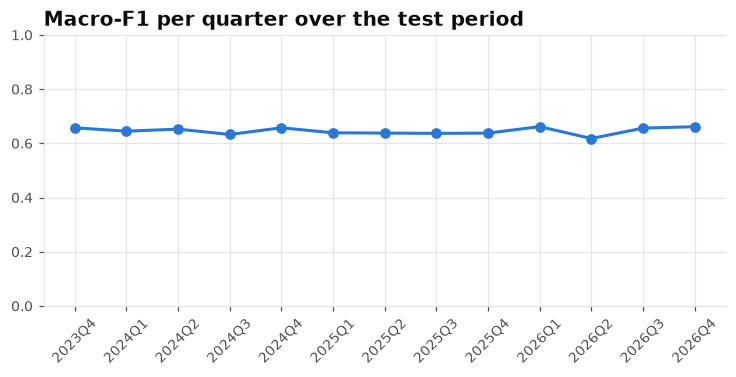

,n,macro_f1
quarter,,
2023Q4,"1,840",0.657
2024Q1,"4,773",0.645
2024Q2,"6,540",0.653
2024Q3,"4,215",0.633
2024Q4,"7,404",0.657
2025Q1,"2,102",0.639
2025Q2,"2,141",0.638
2025Q3,"2,476",0.637
2025Q4,"2,503",0.638


In [11]:
q = test.assign(quarter=test["at"].dt.to_period("Q").astype(str))
drift = q.groupby("quarter").apply(lambda g: pd.Series({"n": len(g),
        "macro_f1": f1_score(g["sentiment"], g["pred"], average="macro")}))
drift = drift[drift["n"] >= 500]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(drift.index, drift["macro_f1"], marker="o", color=BLUE)
ax.set_title("Macro-F1 per quarter over the test period"); ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=45)
save(fig, "02_drift"); plt.show()
drift.style.format({"n": "{:,.0f}", "macro_f1": "{:.3f}"})

Whether performance holds or decays across quarters tells us how often to **retrain**. In production the pipeline would crawl new reviews weekly, track this metric, and retrain when it drops below a threshold.

## 7. Save the model for the demo app (refit on all data)

In [12]:
save_final_model(fitted[best_name], data)
print("Saved", best_name)

Saved TF-IDF word + LogReg


## 8. Next steps
- Fine-tune **PhoBERT** (`vinai/phobert-base-v2`) with word segmentation (VnCoreNLP) — expected gains mostly on the neutral class; needs a GPU.
- Hand-label ~1–2k reviews to get a "clean" test set and measure the effect of label noise precisely.
- Aspect-based sentiment (sentiment per aspect) instead of one label per review — first steps in notebook 03.